# WebMD Drug Reviews – Sentiment Analysis
Naive Bayes vs Logistic Regression vs Random Forest, with CSV outputs for Tableau.

In [ ]:
# Settings: change these to run on another machine or dataset
from pathlib import Path

DATA_FILE    = Path("data/raw/webmd.csv")   # input file (relative to this notebook)
OUTPUT_DIR   = Path("Visualization")        # folder for the Tableau CSVs
SAMPLE_SIZE  = 30000                        # rows to keep so it runs fast
TEST_SIZE    = 0.2                          # 20% of rows for testing
MAX_FEATURES = 5000                         # number of TF-IDF words
SEED         = 42                           # random seed for repeatable results

In [ ]:
# Import the libraries we need
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## Step 1 – Load and clean the data

In [ ]:
# Load the CSV file
df = pd.read_csv(DATA_FILE)

# Drop rows with empty reviews (including reviews that are only spaces)
df["Reviews"] = df["Reviews"].astype(str).str.strip()
df = df[df["Reviews"].ne("") & df["Reviews"].ne("nan")]

# Drop duplicate rows
df = df.drop_duplicates()
print("Rows after cleaning:", len(df))

Rows after cleaning: 320097


## Step 2 – Create the sentiment label

In [ ]:
# Make sure Satisfaction is a number
df["Satisfaction"] = pd.to_numeric(df["Satisfaction"], errors="coerce")

# 4-5 = Positive, 1-2 = Negative, everything else (3) is dropped
df["Sentiment"] = df["Satisfaction"].map({1: "Negative", 2: "Negative", 4: "Positive", 5: "Positive"})
df = df.dropna(subset=["Sentiment"])
print(df["Sentiment"].value_counts())

Sentiment
Positive    148326
Negative    128199
Name: count, dtype: int64


## Step 3 – Take a random sample

In [ ]:
# Keep a random sample so the notebook runs quickly
df = df.sample(n=min(SAMPLE_SIZE, len(df)), random_state=SEED).reset_index(drop=True)
print("Sample size:", len(df))

Sample size: 30000


## Step 4 – Clean the review text

In [ ]:
# Lowercase, then keep only letters and spaces (removes punctuation and numbers)
def clean_text(text):
    return re.sub(r"[^a-z\s]", " ", text.lower())

df["Clean_Review"] = df["Reviews"].apply(clean_text)
df[["Reviews", "Clean_Review"]].head()

,Reviews,Clean_Review
0,Had a double bypass in Dec. feel worse now tha...,had a double bypass in dec feel worse now tha...
1,I had the Mirena IUD inserted six weeks ago fo...,i had the mirena iud inserted six weeks ago fo...
2,"I've been on Ocella for about 3 months. And, ...",i ve been on ocella for about months and ...
3,Ok this is my first day using this presciption...,ok this is my first day using this presciption...
4,This medication makes me a horrible person to ...,this medication makes me a horrible person to ...


## Step 5 – Train/test split and TF-IDF

In [ ]:
# Split 80% train / 20% test, keeping the same Positive/Negative ratio in both
X_train, X_test, y_train, y_test = train_test_split(
    df["Clean_Review"], df["Sentiment"], test_size=TEST_SIZE, random_state=SEED, stratify=df["Sentiment"])

# Turn text into numbers with TF-IDF (learn words from train only)
tfidf = TfidfVectorizer(max_features=MAX_FEATURES, stop_words="english")
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)
print("Train:", X_train_vec.shape, " Test:", X_test_vec.shape)

Train: (24000, 5000)  Test: (6000, 5000)


## Step 6 – Train the 3 models

In [ ]:
# Define the 3 models
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
}

# Train each model and store its predictions on the test set
predictions = {}
for name, model in models.items():
    model.fit(X_train_vec, y_train)
    predictions[name] = model.predict(X_test_vec)
    print("Trained:", name)

Trained: Naive Bayes
Trained: Logistic Regression
Trained: Random Forest


## Step 7 – Evaluate the models

Naive Bayes: Accuracy=0.7693, Precision=0.7701, Recall=0.7693, F1=0.7680


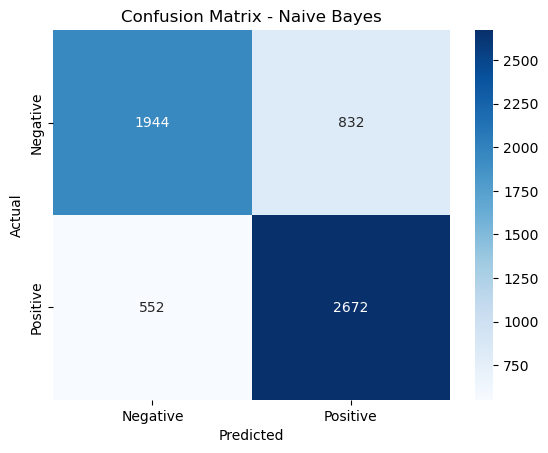

Logistic Regression: Accuracy=0.7903, Precision=0.7901, Recall=0.7903, F1=0.7902


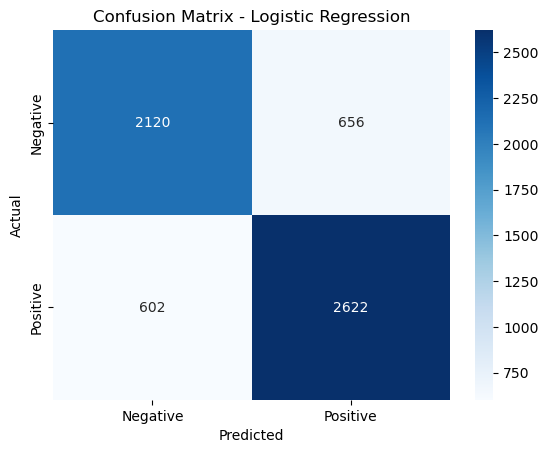

Random Forest: Accuracy=0.7793, Precision=0.7791, Recall=0.7793, F1=0.7791


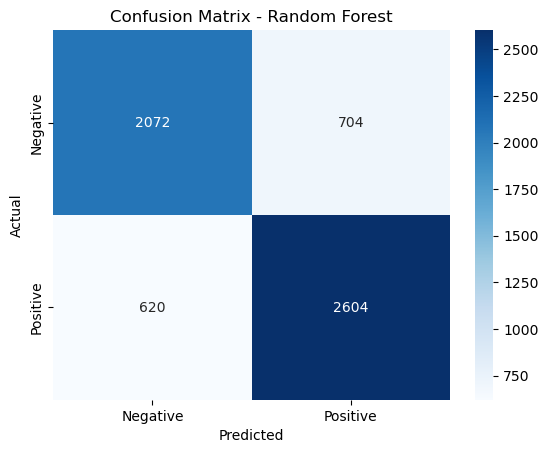

In [ ]:
# Calculate metrics and draw a confusion matrix heatmap for each model
labels = ["Negative", "Positive"]
results, cm_rows = [], []

for name, y_pred in predictions.items():
    # Metrics (weighted average across both classes)
    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted"),
        "Recall": recall_score(y_test, y_pred, average="weighted"),
        "F1": f1_score(y_test, y_pred, average="weighted"),
    }
    results.append(scores)
    print(f"{name}: " + ", ".join(f"{k}={v:.4f}" for k, v in scores.items() if k != "Model"))

    # Confusion matrix heatmap
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.show()

    # Save confusion matrix in long format for Tableau
    for i, actual in enumerate(labels):
        for j, pred in enumerate(labels):
            cm_rows.append({"Model": name, "Actual": actual, "Predicted": pred, "Count": cm[i, j]})

In [ ]:
# Compare the 3 models in one table and pick the best by F1 score
results_df = pd.DataFrame(results).round(4)
best_model = results_df.loc[results_df["F1"].idxmax(), "Model"]
print("Best model:", best_model)
results_df

Best model: Logistic Regression


,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,0.7693,0.7701,0.7693,0.7680
1,Logistic Regression,0.7903,0.7901,0.7903,0.7902
2,Random Forest,0.7793,0.7791,0.7793,0.7791


## Step 8 – Save CSV files for Tableau

In [ ]:
# Create the output folder
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reviews file: test-set rows with actual Sentiment and the best model's prediction
reviews = df.loc[X_test.index, ["Drug", "Condition", "Age", "Sex", "Satisfaction",
                                "Effectiveness", "EaseofUse", "Sentiment"]].copy()
reviews["Predicted"] = predictions[best_model]
reviews.to_csv(OUTPUT_DIR / "tableau_reviews.csv", index=False)

# Model results and confusion matrix files
results_df.to_csv(OUTPUT_DIR / "tableau_model_results.csv", index=False)
pd.DataFrame(cm_rows).to_csv(OUTPUT_DIR / "tableau_confusion_matrix.csv", index=False)
print("Saved files:", [f.name for f in OUTPUT_DIR.glob("*.csv")])

Saved files: ['tableau_confusion_matrix.csv', 'tableau_model_results.csv', 'tableau_reviews.csv']
